# 🧪 LAB: Machine Learning to Predict Concrete Compressive Strength

In this lab, you will apply `PyTorch` to a real-world data problem. You will implement a Neural Network in `PyTorch` using the new functionalities introduced this week and compare its performance with a Support Vector Machine and Linear Regression.

Your goal is to predict the **compressive strength of concrete** (the outcome variable, *Y*) based on a set of input features (*X*), including:
**Cement, Blast Furnace Slag, Fly Ash, Water, Superplasticizer, Coarse Aggregate, Fine Aggregate, and Age.**

This dataset and problem are based on the following paper:

- I-Cheng Yeh, "Modeling of strength of high performance concrete using artificial neural networks," Cement and Concrete Research, Vol. 28, No. 12, pp. 1797-1808 (1998). [Link to the paper](yeh1998.pdf).


---

**Collaboration Note**: This assignment is designed to support collaborative work. We encourage you to divide tasks among group members so that everyone can contribute meaningfully. Many components of the assignment can be approached in parallel or split logically across team members. Good coordination and thoughtful integration of your work will lead to a stronger final result.

---

In total, this lab assignment will be worth **100 points**.

--- 
**Submission notes**:

* Write down all group members' names, or at least the group name (if you have one and you previously provided it), in the first cell of the notebook.

* Verify that the notebook runs as expected and that all required outputs are included.

NAME(s) = ""

## 0. Overall Instructions 

In this lab, you will work with three models: a **Neural Network**, a **Support Vector Machine (SVM)**, and some form of **Linear Regression**. Each should meet the following requirements:

- **Do not tune the models**. For example, for the Neural Network, choose any number of layers and hidden units you prefer; for the SVM, select a kernel of your choice (e.g., linear, RBF, polynomial), etc.

- **Evaluate model performance using k-fold cross-validation**. That is, run each model using a chosen number of folds (*k*), and report the average performance across all folds. You may select the value of *k* that you want.

- **Be careful with data preprocessing**. Apply all preprocessing steps properly to avoid data leakage (e.g. standardizing features before data splitting)

## 1. Pre-implementation Group Discussion (15 points)

In your group, discuss, agree on, and elaborate the following points:

- **Descriptive analysis**. Identify what exploratory or descriptive analyses you can perform to better understand the relationship between each input variable and the outcome. Consider both visual (e.g., scatter plots, histograms) and statistical summaries.

- **Data preprocessing**. Decide what preprocessing steps are necessary given that you will be using neural networks. 

- **Model configuration**. Specify which cost function and output layer activation are most appropriate for your problem type (e.g., regression vs. classification). Explain your reasoning based on the nature of the outcome variable.

- **Performance evaluation**. Describe how you will perform k-fold cross-validation to assess your model’s performance. Include how you will divide the data, compute metrics across folds, and report the final averaged results.

**1) Descriptive analysis.**

We will print a summary table and plot a histogram of every variable to see the scales and the skew. We expect slag, fly ash and superplasticizer to have a spike at zero, since many mixes do not contain them, and age to be right skewed because most specimens are tested at 3, 7 or 28 days. To see how each input relates to strength we will make a scatter plot of strength against each of the eight inputs, plus one against log(age), since the effect of age should flatten out as the concrete cures. We use scatter plots because they show the shape of a relationship, which a single correlation number would hide. We will also check for missing values and duplicate rows. Duplicates matter for k-fold because the same mix can land in both the training and the validation fold. We stick to the eight raw features the lab gives us and do not add the water to cement ratios from Yeh (1998).

**2) Data preprocessing.**

We standardize the inputs because they are on very different scales (coarse aggregate is around 1000, superplasticizer is mostly under 10 and age runs from 1 to 365), and unscaled inputs make training slower and less stable even with Adam. We standardize y too, so the MSE and the gradients are around 1, and we convert predictions back to MPa before computing any metric so the errors can be read directly. Both scalers are fit on the training folds only, inside each fold, because scaling before the split would let the validation rows influence the mean and standard deviation. There are no missing values and every column is numeric, so nothing else is needed. We leave age as it is and add no features, so the network has to find any nonlinearity itself and every model sees the same inputs.

**3) Model configuration.**

Strength is continuous, so this is a regression problem and we use `nn.MSELoss`. The output layer is one unit with no activation (`nn.Identity`). A sigmoid would cap predictions at 1, which cannot reach 80 MPa, and a ReLU could never predict the negative values a standardized y takes for below average mixes. The hidden layer uses `nn.ReLU`, with one hidden layer of 8 units as in Yeh (1998). The lab says not to tune, so we picked Adam with a learning rate of 0.01, a batch size of 32 and 200 epochs once and kept them for every fold.

**4) Performance evaluation.**

We use `KFold` with k = 5, shuffled with a fixed seed, so the neural network, the scikit-learn replication, the SVM and the linear regression all get the same folds. In each fold we fit the scalers on the four training folds, train a new network for a fixed number of epochs, predict the held out fold and convert the predictions back to MPa. We do not stop early based on the validation fold, because that would tune the model on the data we judge it by. We record R², RMSE and MAE on the validation fold and R² on the training folds, then report the mean and standard deviation across the five folds. R² is what Yeh reports, so it lets us compare with the paper. One caveat is that random folds are probably a little optimistic. In the paper, holding out whole data sources dropped the test R² from about 0.91 to between 0.81 and 0.90.

## 2. Descriptive analysis (10 points)

Apply the descriptive analyses that your group agreed upon in the previous section.

**Load the dataset before beginning the descriptive analysis; you will also use it in the following sections.**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("data/concrete_data.csv")

# the raw headers are long and have stray spaces, so shorten them
df.columns = ["cement", "slag", "fly_ash", "water", "superplasticizer", "coarse_agg", "fine_agg", "age", "strength"]
features = df.columns[:-1].tolist()

print(f"Rows: {len(df)}, columns: {df.shape[1]}")
print(f"Missing values: {df.isna().sum().sum()}")
print(f"Duplicate rows: {df.duplicated().sum()}")
df.describe().T.round(2)

Rows: 1030, columns: 9
Missing values: 0
Duplicate rows: 25


,count,mean,std,min,25%,50%,75%,max
cement,1030.0,281.17,104.51,102.00,192.38,272.90,350.00,540.0
slag,1030.0,73.90,86.28,0.00,0.00,22.00,142.95,359.4
fly_ash,1030.0,54.19,64.00,0.00,0.00,0.00,118.27,200.1
water,1030.0,181.57,21.36,121.75,164.90,185.00,192.00,247.0
superplasticizer,1030.0,6.20,5.97,0.00,0.00,6.35,10.16,32.2
coarse_agg,1030.0,972.92,77.75,801.00,932.00,968.00,1029.40,1145.0
fine_agg,1030.0,773.58,80.18,594.00,730.95,779.51,824.00,992.6
age,1030.0,45.66,63.17,1.00,7.00,28.00,56.00,365.0
strength,1030.0,35.82,16.71,2.33,23.71,34.44,46.14,82.6


In [2]:
# share of rows where each input is exactly zero
(df[features] == 0).mean().round(2)

cement              0.00
slag                0.45
fly_ash             0.55
water               0.00
superplasticizer    0.37
coarse_agg          0.00
fine_agg            0.00
age                 0.00
dtype: float64

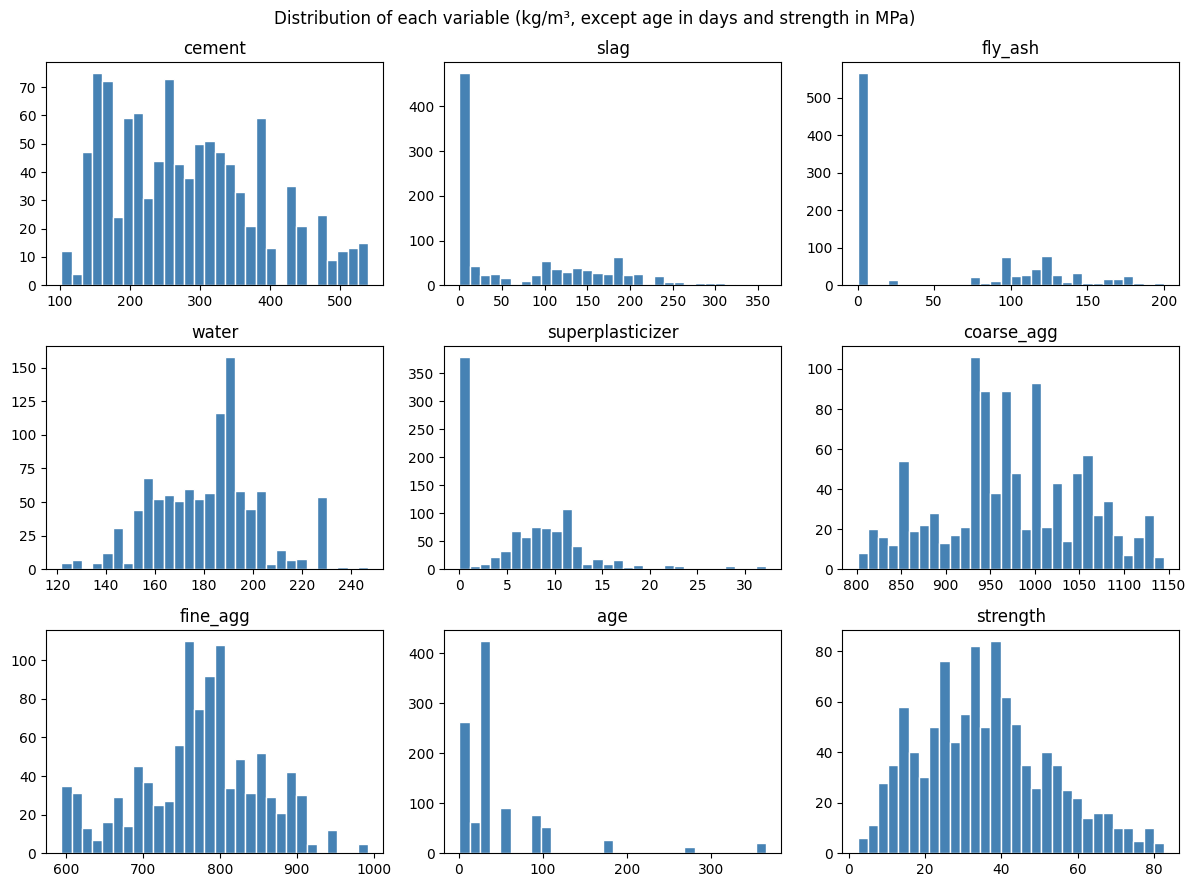

In [3]:
fig, axes = plt.subplots(3, 3, figsize=(12, 9))
for ax, col in zip(axes.ravel(), df.columns):
    ax.hist(df[col], bins=30, color="steelblue", edgecolor="white")
    ax.set_title(col)
fig.suptitle("Distribution of each variable (kg/m³, except age in days and strength in MPa)")
plt.tight_layout()
plt.show()

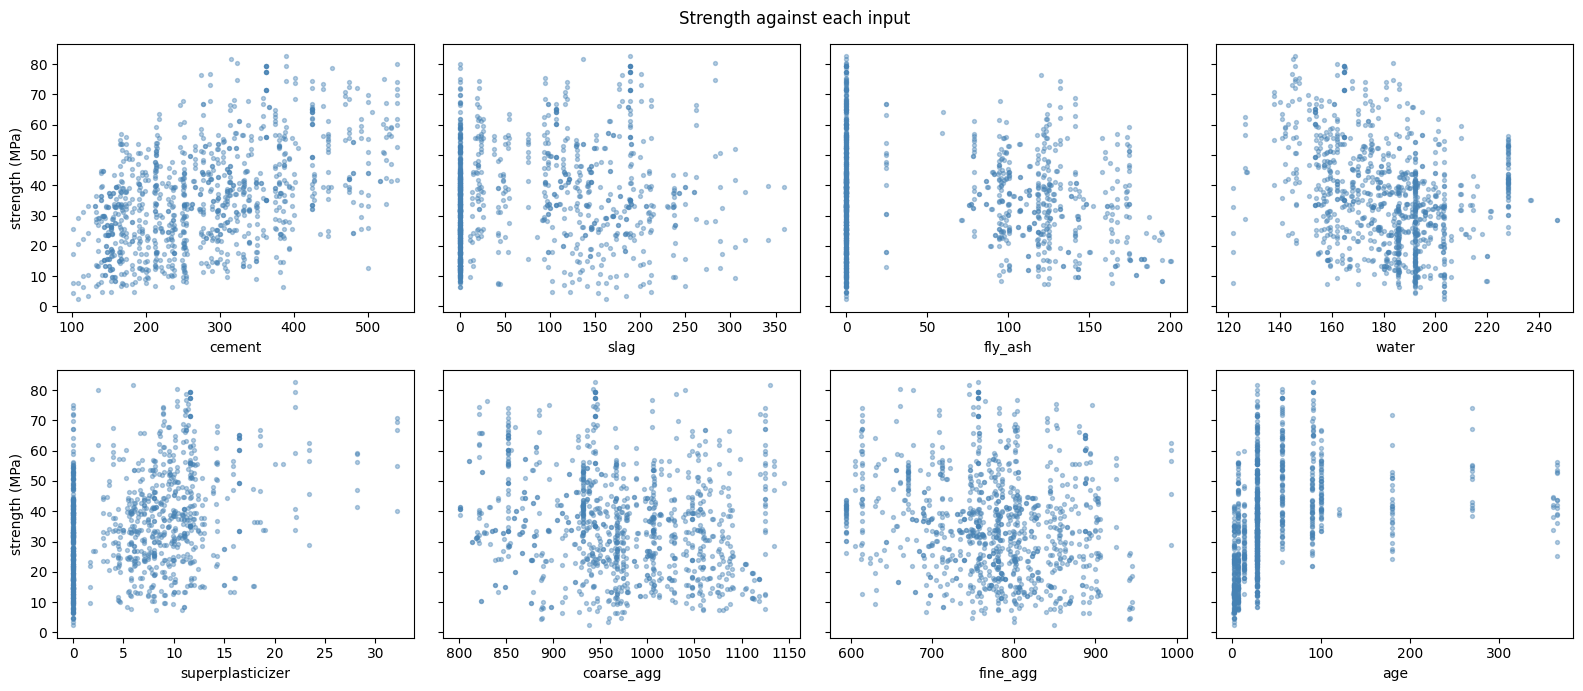

In [4]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7), sharey=True)
for ax, col in zip(axes.ravel(), features):
    ax.scatter(df[col], df["strength"], s=8, alpha=0.4, color="steelblue")
    ax.set_xlabel(col)
axes[0, 0].set_ylabel("strength (MPa)")
axes[1, 0].set_ylabel("strength (MPa)")
fig.suptitle("Strength against each input")
plt.tight_layout()
plt.show()

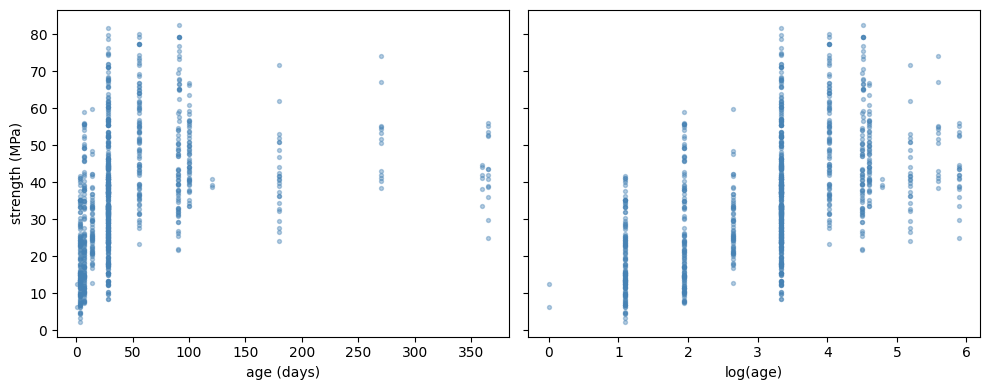

,count,mean
age,,
3,134,19.0
7,126,26.1
14,62,28.8
28,425,36.7
56,91,51.9
90,54,40.5
91,22,69.8
100,52,47.7
180,26,41.7


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
axes[0].scatter(df["age"], df["strength"], s=8, alpha=0.4, color="steelblue")
axes[0].set_xlabel("age (days)")
axes[0].set_ylabel("strength (MPa)")
axes[1].scatter(np.log(df["age"]), df["strength"], s=8, alpha=0.4, color="steelblue")
axes[1].set_xlabel("log(age)")
plt.tight_layout()
plt.show()

# mean strength at each age that has at least 20 specimens
by_age = df.groupby("age")["strength"].agg(["count", "mean"]).round(1)
by_age[by_age["count"] >= 20]

**What the descriptive analysis shows.**

The data has 1030 rows, no missing values and 25 duplicate rows (about 2.4%). We keep them, so a few validation rows have an exact copy in the training folds, which slightly flatters the scores. As expected, slag is zero in 45% of mixes, fly ash in 55% and superplasticizer in 37%. Age is the most skewed column, with a mean of 46 days and a median of 28. Strength runs from 2.3 to 82.6 MPa with a mean of 35.8.

In the scatter plots cement has the clearest positive trend and water the clearest negative one, which fits the water to cement idea in Yeh's paper. Superplasticizer is positive among the mixes that contain it, but slag, fly ash and both aggregates show no clear pattern. Every plot has wide vertical scatter, so no single input explains strength. Age is the most nonlinear. Mean strength goes from 19 MPa at 3 days to 37 at 28 days and 52 at 56 days, then levels off around 40 to 50. The log axis makes that curve easier to see. This kind of curved, interacting structure is what we expect a linear model to struggle with and the neural network to pick up.

## 3. Neural Network (40 points)

Implement a neural network as you did in the previous lab, but this time leverage the new functionalities introduced this week. Specifically:

- Your class implementing the neural network should inherit from nn.Module.

- Use `nn.Linear` for the linear transformations between layers, `nn.ReLU` for the hidden-layer activations, and the appropriate activation function for the output layer (e.g., `nn.Sigmoid` for binary classification).

- Use the appropriate cost function from `torch.nn` for your task (e.g., `nn.MSELoss`, `nn.BCELoss`).

- Use Adam from `torch.optim` as the optimizer.

- Use `DataLoader` to efficiently do batch processing. You may choose the batch size freely.

Once you have implemented this class, create an instance of it, then train and evaluate your model on the lab dataset.

**Remember to follow the general requirements regarding model tuning, evaluation, and data preprocessing described earlier.**

In [6]:
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import KFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

X = df[features].values
y = df["strength"].values

In [7]:
class ConcreteNN(nn.Module):
    """One hidden layer ReLU network for regression. The output is a single unit with no activation."""

    def __init__(self, input_size, hidden_size):
        super().__init__()
        self.hidden = nn.Linear(input_size, hidden_size)
        self.relu = nn.ReLU()
        self.output = nn.Linear(hidden_size, 1)
        self.output_activation = nn.Identity()  # strength is unbounded, so no squashing

    def forward(self, x):
        return self.output_activation(self.output(self.relu(self.hidden(x))))

In [8]:
HIDDEN_SIZE = 8
EPOCHS = 200
LEARNING_RATE = 0.01
BATCH_SIZE = 32

def evaluate(y_true, y_pred):
    # all metrics are in the original MPa units
    return {
        "r2": r2_score(y_true, y_pred),
        "rmse": mean_squared_error(y_true, y_pred) ** 0.5,
        "mae": mean_absolute_error(y_true, y_pred),
    }

def train_nn(X_train, y_train):
    # y_train is the standardized target with shape (n, 1)
    model = ConcreteNN(X_train.shape[1], HIDDEN_SIZE)
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    loss_fn = nn.MSELoss()
    loader = DataLoader(TensorDataset(X_train, y_train), batch_size=BATCH_SIZE, shuffle=True)

    for epoch in range(EPOCHS):
        for X_batch, y_batch in loader:
            optimizer.zero_grad()
            loss = loss_fn(model(X_batch), y_batch)
            loss.backward()
            optimizer.step()
    return model.eval()

# the same folds are reused for every model in this lab
kf = KFold(n_splits=5, shuffle=True, random_state=42)

In [9]:
nn_rows = []
for fold, (train_idx, val_idx) in enumerate(kf.split(X), start=1):
    torch.manual_seed(fold)

    # fit both scalers on the training folds only to avoid leakage
    x_scaler = StandardScaler().fit(X[train_idx])
    y_scaler = StandardScaler().fit(y[train_idx].reshape(-1, 1))

    X_train = torch.tensor(x_scaler.transform(X[train_idx]), dtype=torch.float32)
    X_val = torch.tensor(x_scaler.transform(X[val_idx]), dtype=torch.float32)
    y_train = torch.tensor(y_scaler.transform(y[train_idx].reshape(-1, 1)), dtype=torch.float32)

    model = train_nn(X_train, y_train)

    # back to MPa before computing any metric
    with torch.no_grad():
        pred_train = y_scaler.inverse_transform(model(X_train).numpy())
        pred_val = y_scaler.inverse_transform(model(X_val).numpy())

    train_metrics = evaluate(y[train_idx], pred_train)
    val_metrics = evaluate(y[val_idx], pred_val)
    nn_rows.append({"fold": fold, "train_r2": train_metrics["r2"], "val_r2": val_metrics["r2"],
                    "val_rmse": val_metrics["rmse"], "val_mae": val_metrics["mae"]})

nn_results = pd.DataFrame(nn_rows).set_index("fold")
nn_results.round(3)

,train_r2,val_r2,val_rmse,val_mae
fold,,,,
1,0.883,0.858,6.049,4.780
2,0.894,0.877,6.428,4.625
3,0.895,0.867,6.133,4.631
4,0.888,0.880,5.820,4.564
5,0.872,0.826,6.411,5.073


In [10]:
summary = pd.DataFrame({"mean": nn_results.mean(), "std": nn_results.std()}).round(3)
summary

,mean,std
train_r2,0.887,0.009
val_r2,0.861,0.022
val_rmse,6.168,0.256
val_mae,4.735,0.205


**Neural network results.**

Over the five folds the network gets a validation R² of 0.861 (std 0.022), an RMSE of 6.17 MPa and an MAE of 4.74 MPa, compared with a standard deviation of 16.7 MPa in strength itself. Training R² is 0.887, a gap of only 0.026, so we see no sign of overfitting. The folds range from 0.826 (fold 5) to 0.880 (fold 4). With about 206 mixes per fold, a few badly predicted strong mixes can move one fold, which is why we average over all five. The paper reports 0.908 to 0.922 on random splits, which is higher than ours, but it used a smaller version of the data (727 mixes), its own training schedule, and we did not tune anything. The comparison with the SVM and linear regression is in Section 5.

## 4. Replication (10 points)

Replicate your neural network experiment using the corresponding model class from `scikit-learn`: https://scikit-learn.org/stable/api/sklearn.neural_network.html. Be sure to apply the same neural network architecture as well as the same procedures for model evaluation and preprocessing to ensure a fair comparison.

**Remember**: Follow the general requirements regarding model tuning, evaluation, and data preprocessing described earlier.

In [11]:
import warnings
from sklearn.neural_network import MLPRegressor
from sklearn.exceptions import ConvergenceWarning

# sklearn warns when it hits max_iter, which is expected since we train for a fixed number of epochs
warnings.filterwarnings("ignore", category=ConvergenceWarning)

sk_rows = []
for fold, (train_idx, val_idx) in enumerate(kf.split(X), start=1):
    # same scaling procedure as the PyTorch version, fit on the training folds only
    x_scaler = StandardScaler().fit(X[train_idx])
    y_scaler = StandardScaler().fit(y[train_idx].reshape(-1, 1))

    X_train = x_scaler.transform(X[train_idx])
    X_val = x_scaler.transform(X[val_idx])
    y_train = y_scaler.transform(y[train_idx].reshape(-1, 1)).ravel()

    # same architecture and settings as ConcreteNN; alpha=0 removes the default L2 penalty
    # and n_iter_no_change=EPOCHS stops it from quitting early, so it trains for all 200 epochs
    sk_model = MLPRegressor(hidden_layer_sizes=(HIDDEN_SIZE,), activation="relu", solver="adam",
                            learning_rate_init=LEARNING_RATE, batch_size=BATCH_SIZE, max_iter=EPOCHS,
                            alpha=0, n_iter_no_change=EPOCHS, random_state=fold)
    sk_model.fit(X_train, y_train)

    pred_train = y_scaler.inverse_transform(sk_model.predict(X_train).reshape(-1, 1))
    pred_val = y_scaler.inverse_transform(sk_model.predict(X_val).reshape(-1, 1))

    train_metrics = evaluate(y[train_idx], pred_train)
    val_metrics = evaluate(y[val_idx], pred_val)
    sk_rows.append({"fold": fold, "train_r2": train_metrics["r2"], "val_r2": val_metrics["r2"],
                    "val_rmse": val_metrics["rmse"], "val_mae": val_metrics["mae"]})

sk_results = pd.DataFrame(sk_rows).set_index("fold")
sk_results.round(3)

,train_r2,val_r2,val_rmse,val_mae
fold,,,,
1,0.891,0.850,6.215,4.978
2,0.909,0.884,6.241,4.570
3,0.899,0.866,6.150,4.432
4,0.888,0.846,6.582,4.883
5,0.899,0.848,5.990,4.621


In [12]:
sk_summary = pd.DataFrame({"mean": sk_results.mean(), "std": sk_results.std()}).round(3)

# put the two implementations side by side
pd.concat({"PyTorch": summary["mean"], "scikit-learn": sk_summary["mean"]}, axis=1)

,PyTorch,scikit-learn
train_r2,0.887,0.897
val_r2,0.861,0.859
val_rmse,6.168,6.236
val_mae,4.735,4.697


**Replication results.**

We used `MLPRegressor` with the same architecture (one hidden layer of 8 ReLU units, linear output), the same Adam settings, batch size 32 and 200 epochs, and the same folds and scaling as the PyTorch version. Two defaults had to be changed to make it a fair comparison. `alpha` is an L2 penalty that is on by default and PyTorch has no equivalent in our code, so we set it to 0, and the default early stopping rule would end training before 200 epochs, so we set `n_iter_no_change` to 200.

The results are essentially the same. Validation R² is 0.859 (std 0.016) against 0.861 for PyTorch, RMSE is 6.24 MPa against 6.17 and MAE is 4.70 against 4.74. Those differences are far smaller than the fold to fold spread, so we would not call either implementation better. Both use the same model, the same loss and the same optimizer, so this is what we expected. The small differences probably come from the random weight initialisation, which each library does differently, and from the order of the shuffled batches. The per fold numbers also move around a bit, for example fold 4 is 0.880 in PyTorch and 0.846 in scikit-learn, so a single fold is not a reliable way to compare two runs.

## 5. Comparison (20 points)

Apply a Support Vector Machine (SVM) and Linear Regression model to the dataset, and compare their performance with that of your Neural Network.

Discuss any similarities or differences you observe in their results and provide possible explanations for these patterns.

Be sure to apply the k-fold cross-validation procedure to ensure a fair comparison across all models.

**Remember**: Follow the general requirements regarding model tuning, evaluation, and data preprocessing described earlier.

In [13]:
# USE AS MANY CELLS AS NEEDED

## 6. Collaboration Reflection (5 points)

As a group, identify **one specific challenge or inefficiency** you encountered while working on this lab. In 3–5 sentences:

1. Briefly describe what happened and how it affected your work.
2. Identify one concrete action your group will take to avoid or better manage this issue in the next lab.

If your group encountered no major problem, identify one aspect of your collaboration that could still be improved.

YOUR TEXT HERE